# Render Rollout Frames

Load rollouts from the multi_prior_rollout H5 file, select one, and render 5 evenly spaced frames.

In [19]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import h5py
import numpy as np
import mujoco
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from vnl_playground.tasks.rodent import consts as rodent_consts

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
# Load the H5 file
h5_path = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/scratch/multi_prior_rollouts/goldenrodent_jax/rollout_data.h5"
)
h5f = h5py.File(h5_path, "r")

In [21]:
# List all available rollouts
rollout_index = []
for var_name in sorted(h5f.keys()):
    if var_name == "metadata":
        continue
    var_group = h5f[var_name]
    for pose_name in sorted(var_group.keys()):
        n_rollouts = var_group[pose_name]["qpos"].shape[0]
        n_steps = var_group[pose_name]["qpos"].shape[1]
        for i in range(n_rollouts):
            rollout_index.append({
                "idx": len(rollout_index),
                "variance": var_name,
                "pose": pose_name,
                "rollout": i,
                "steps": n_steps,
            })

print(f"Total rollouts available: {len(rollout_index)}")
print("\nVariance groups and poses:")
for var_name in sorted(h5f.keys()):
    if var_name == "metadata":
        continue
    poses = sorted(h5f[var_name].keys())
    n = h5f[var_name][poses[0]]["qpos"].shape[0]
    print(f"  {var_name}: {len(poses)} poses, {n} rollouts each")

Total rollouts available: 14721

Variance groups and poses:
  deterministic: 21 poses, 1 rollouts each
  logvar_-0.5: 21 poses, 100 rollouts each
  logvar_-1.0: 21 poses, 100 rollouts each
  logvar_-2.0: 21 poses, 100 rollouts each
  logvar_-3.0: 21 poses, 100 rollouts each
  logvar_-4.0: 21 poses, 100 rollouts each
  logvar_0.0: 21 poses, 100 rollouts each
  predicted_logvar: 21 poses, 100 rollouts each


In [22]:
# Select a rollout
variance = "logvar_-3.0"  # e.g. "deterministic", "logvar_-2.0", "predicted_logvar"
pose = "neutral"              # e.g. "neutral", "clip1_frame0", "clip3_frame0"
rollout_idx = 1               # which rollout within this variance/pose

qpos = h5f[variance][pose]["qpos"][rollout_idx]  # (max_steps, 74)
print(f"Selected: {variance} / {pose} / rollout {rollout_idx}")
print(f"qpos shape: {qpos.shape}")

Selected: logvar_-3.0 / neutral / rollout 1
qpos shape: (1000, 74)


In [23]:
# XML paths (override these to use different models)
walker_xml = str(rodent_consts.RODENT_NO_TAIL_COLLISION_XML)
arena_xml = str(rodent_consts.ARENA_XML_PATH)

# Build combined arena+rodent model (matches the 74 DOF qpos from rollouts)
arena_spec = mujoco.MjSpec.from_file(arena_xml)
rodent_spec = mujoco.MjSpec.from_file(walker_xml)

frame = arena_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
spawn_body = frame.attach_body(rodent_spec.body("walker"), "", suffix="-rodent")
spawn_body.add_freejoint(name="root")

model = arena_spec.compile()
data = mujoco.MjData(model)

print(f"Walker XML: {walker_xml}")
print(f"Arena XML:  {arena_xml}")
print(f"Model qpos dim: {model.nq} (H5 qpos dim: {qpos.shape[1]})")

render_height = 480
render_width = 640
camera = "close_profile-rodent"  # suffix appended during attach

renderer = mujoco.Renderer(model, height=render_height, width=render_width)
cam_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_CAMERA, camera)
print(f"Using camera: {camera} (id={cam_id})")

Walker XML: /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/rodent_no_tail_collisions.xml
Arena XML:  /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/arena.xml
Model qpos dim: 74 (H5 qpos dim: 74)
Using camera: close_profile-rodent (id=0)


In [25]:
# Render evenly spaced frames over a configurable time range
num_frames = 4
t_start = 0                    # first timestep to render
t_end = 999     # last timestep to render

frame_indices = np.linspace(t_start, t_end, num_frames, dtype=int)

frames = []
for t in frame_indices:
    data.qpos[:] = np.array(qpos[t])
    mujoco.mj_forward(model, data)
    renderer.update_scene(data, camera=cam_id)
    frame = renderer.render()
    frames.append(frame.copy())

print(f"Rendered {num_frames} frames at timesteps: {frame_indices.tolist()}")

Rendered 4 frames at timesteps: [0, 333, 666, 999]


In [26]:
# Render video of the rollout
import mediapy as media

video_t_start = 0
video_t_end = qpos.shape[0]
video_fps = 50  # matches 50Hz simulation

video_indices = np.arange(video_t_start, video_t_end)
video_frames = []
for t in video_indices:
    data.qpos[:] = np.array(qpos[t])
    mujoco.mj_forward(model, data)
    renderer.update_scene(data, camera=cam_id)
    video_frames.append(renderer.render().copy())

media.show_video(video_frames, fps=video_fps)

This browser does not support the video tag.


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/rollout_frames_logvar_-3.0_neutral_1.pdf and .svg and .png


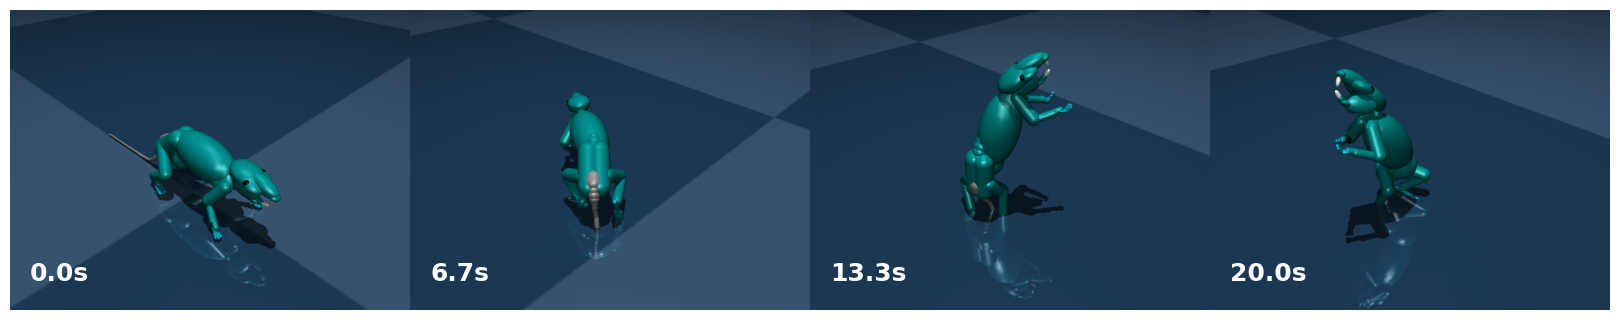

In [90]:
# Set the RGB color for the frame border (0-255 scale)
accent_rgb = (0, 170, 188)
accent_color = tuple(c / 255 for c in accent_rgb)

# Set the RGB color for the time labels (0-255 scale)
label_rgb = (255, 255, 255)
label_color = tuple(c / 255 for c in label_rgb)

# Save path and filename
save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation")
save_name = f"rollout_frames_{variance}_{pose}_{rollout_idx}"

fig, axes = plt.subplots(1, num_frames, figsize=(num_frames * 4, 4))
plt.subplots_adjust(wspace=0, hspace=0)

for ax, frame, t in zip(axes, frames, frame_indices):
    ax.imshow(frame)
    ax.text(
        0.05, 0.08, f"{t / 50:.1f}s",
        transform=ax.transAxes,
        fontsize=18, fontweight="bold",
        color=label_color,
        va="bottom", ha="left",
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

plt.tight_layout(pad=0)

# Save as PDF and SVG
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight", pad_inches=0)
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight", pad_inches=0)
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight", pad_inches=0)
print(f"Saved to {save_dir / save_name}.pdf and .svg and .png")

plt.show()

Using camera: trail_overview (id=0)
Added 120 line segments (every 5 steps)
Rendered 8 poses at timesteps: [0, 85, 171, 257, 342, 428, 514, 600]
Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/rollout_trail_logvar_-3.0_neutral_1.pdf and .svg and .png


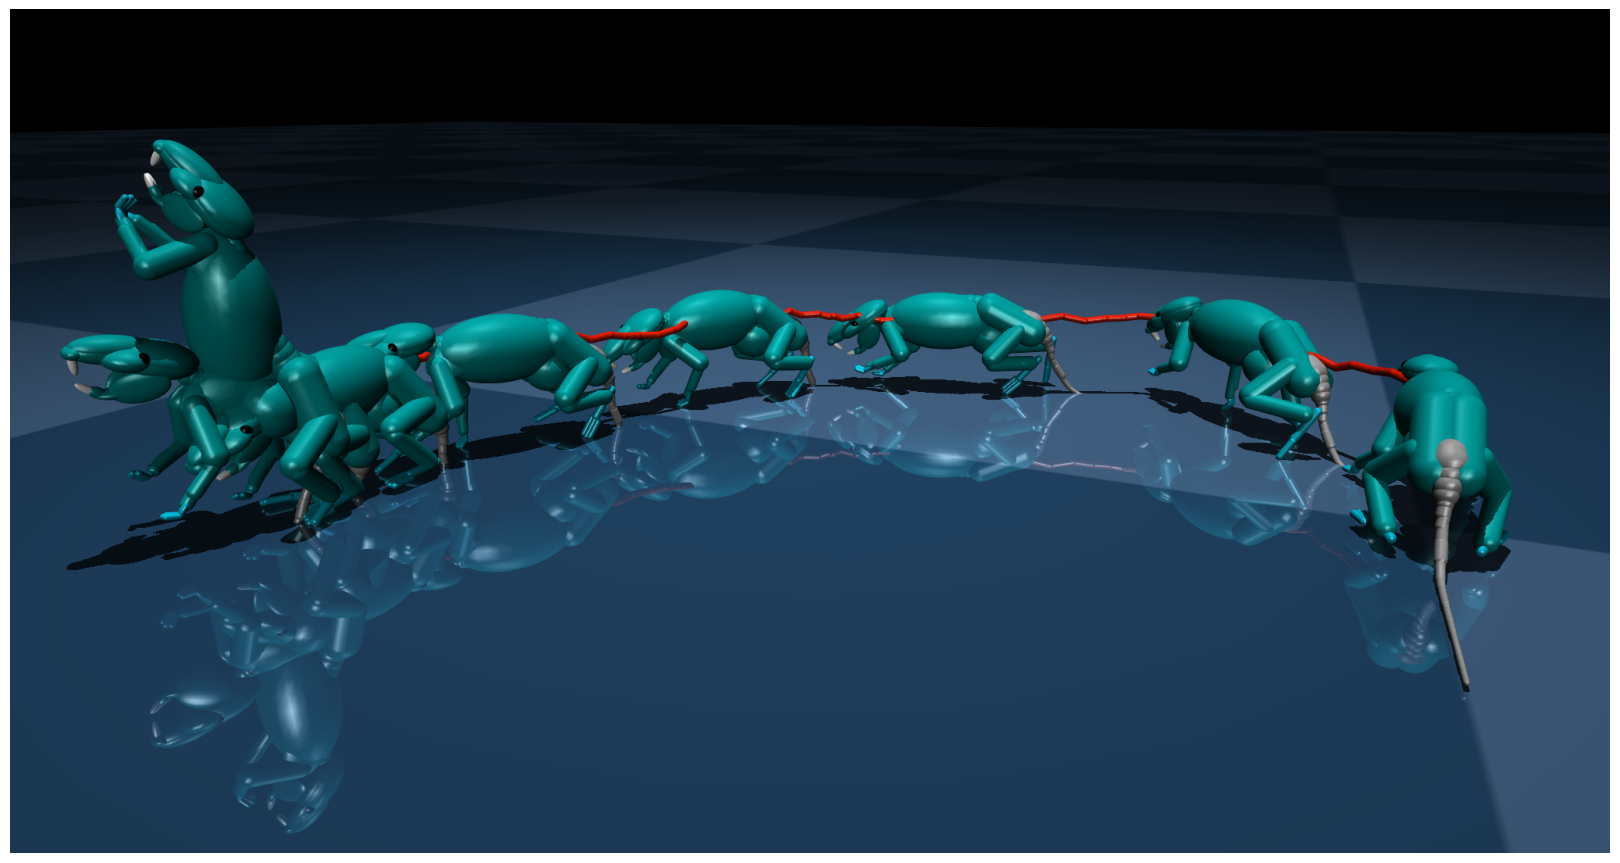

In [99]:
# Motion trail: render multiple consecutive poses in a single frame
trail_num_frames = 8          # number of rodent copies to place
trail_t_start = 0              # first timestep
trail_t_end = 600              # last timestep

# Trajectory trace line (capsule segments along torso center)
trail_line_step = 5            # connect positions every N timesteps
trail_line_radius = 0.003      # line thickness
trail_line_rgb = (189, 19, 0) # line color (0-255 scale)
trail_line_alpha = 0.8         # line opacity (0-1)

# Camera (world coordinates)
trail_cam_pos = [-0.7, 0.1, 0.25]     # camera position [x, y, z]
trail_cam_lookat = [0.0, 0.425, 0.0]   # point the camera looks at [x, y, z]
trail_cam_fovy = 45                    # vertical field of view (degrees)

# Render resolution
trail_render_height = 1080
trail_render_width = 2048

trail_save_name = f"rollout_trail_{variance}_{pose}_{rollout_idx}"
trail_indices = np.linspace(trail_t_start, trail_t_end, trail_num_frames, dtype=int)
trail_line_rgba = [c / 255 for c in trail_line_rgb] + [trail_line_alpha]

# Compute torso xpos at each trace timestep using the single-rodent model
torso_body_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "torso-rodent")
line_timesteps = np.arange(trail_t_start, trail_t_end + 1, trail_line_step)
torso_positions = []
for t in line_timesteps:
    data.qpos[:] = np.array(qpos[t])
    mujoco.mj_forward(model, data)
    torso_positions.append(data.xpos[torso_body_id].copy())

# Build model with multiple rodent copies
trail_spec = mujoco.MjSpec.from_file(arena_xml)
for i in range(trail_num_frames):
    rodent_spec_i = mujoco.MjSpec.from_file(walker_xml)
    frame_i = trail_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    body_i = frame_i.attach_body(rodent_spec_i.body("walker"), "", suffix=f"-t{i}")
    body_i.add_freejoint(name=f"root-t{i}")

# Add trajectory trace as capsule line segments between consecutive torso positions
for j in range(len(torso_positions) - 1):
    p1 = torso_positions[j].tolist()
    p2 = torso_positions[j + 1].tolist()
    trail_spec.worldbody.add_geom(
        name=f"line_seg_{j}",
        type=mujoco.mjtGeom.mjGEOM_CAPSULE,
        fromto=[*p1, *p2],
        size=[trail_line_radius, 0, 0],
        rgba=trail_line_rgba,
        contype=0,
        conaffinity=0,
    )

# Compute camera orientation from pos and lookat
cam_pos = np.array(trail_cam_pos, dtype=float)
cam_lookat = np.array(trail_cam_lookat, dtype=float)
look_dir = cam_lookat - cam_pos
cam_z = -look_dir / np.linalg.norm(look_dir)  # camera -z points toward scene
world_up = np.array([0.0, 0.0, 1.0])
cam_x = np.cross(world_up, cam_z)
cam_x /= np.linalg.norm(cam_x)
cam_y = np.cross(cam_z, cam_x)
R = np.column_stack([cam_x, cam_y, cam_z])
trace = R[0, 0] + R[1, 1] + R[2, 2]
s = 2.0 * np.sqrt(1.0 + trace)
cam_quat = [0.25 * s, (R[2, 1] - R[1, 2]) / s, (R[0, 2] - R[2, 0]) / s, (R[1, 0] - R[0, 1]) / s]

overview_cam = trail_spec.worldbody.add_camera(name="trail_overview")
overview_cam.pos = cam_pos.tolist()
overview_cam.quat = cam_quat
overview_cam.fovy = trail_cam_fovy

# Add overhead light to the spec
overhead = trail_spec.worldbody.add_light(name="overhead")
overhead.pos = [0.0, 0.425, 3.0]
overhead.dir = [0, 0, -1]
overhead.diffuse = [1.0, 1.0, 1.0]
overhead.specular = [0.3, 0.3, 0.3]

trail_model = trail_spec.compile()

# Disable ALL tracking lights (each rodent copy brings one)
for i in range(trail_model.nlight):
    name = mujoco.mj_id2name(trail_model, mujoco.mjtObj.mjOBJ_LIGHT, i)
    if name and "tracking_light" in name:
        trail_model.light_diffuse[i] = [0, 0, 0]
        trail_model.light_specular[i] = [0, 0, 0]

trail_cam_id = mujoco.mj_name2id(
    trail_model, mujoco.mjtObj.mjOBJ_CAMERA, "trail_overview"
)
print(f"Using camera: trail_overview (id={trail_cam_id})")
print(f"Added {len(torso_positions) - 1} line segments (every {trail_line_step} steps)")

trail_data = mujoco.MjData(trail_model)

# Set each copy's qpos to a different timestep
nq_single = model.nq  # 74 DOF per rodent
for i, t in enumerate(trail_indices):
    start = i * nq_single
    trail_data.qpos[start : start + nq_single] = np.array(qpos[t])

mujoco.mj_forward(trail_model, trail_data)

# Render
trail_renderer = mujoco.Renderer(trail_model, height=trail_render_height, width=trail_render_width)
trail_renderer.update_scene(trail_data, camera=trail_cam_id)
trail_frame = trail_renderer.render().copy()
trail_renderer.close()

# Display and save
fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(trail_frame)
ax.axis("off")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"{trail_save_name}.pdf", bbox_inches="tight", pad_inches=0)
fig.savefig(save_dir / f"{trail_save_name}.svg", bbox_inches="tight", pad_inches=0)
fig.savefig(save_dir / f"{trail_save_name}.png", bbox_inches="tight", pad_inches=0)
print(f"Rendered {trail_num_frames} poses at timesteps: {trail_indices.tolist()}")
print(f"Saved to {save_dir / trail_save_name}.pdf and .svg and .png")

plt.show()